# 1. Data Analysis and Exploration
## AG News Dataset Analysis

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import AGNewsLoader

sns.set_style('whitegrid')
%matplotlib inline

## Load Dataset

In [2]:
# Load AG News data
loader = AGNewsLoader(data_path='../data/raw')
train_df, test_df = loader.prepare_dataset()

print(f"Training samples: {len(train_df)}")
print(f"Test samples: {len(test_df)}")
print(f"\nColumns: {train_df.columns.tolist()}")

Training samples: 120000
Test samples: 7600

Columns: ['class', 'title', 'description', 'text', 'class_name']


## Class Distribution

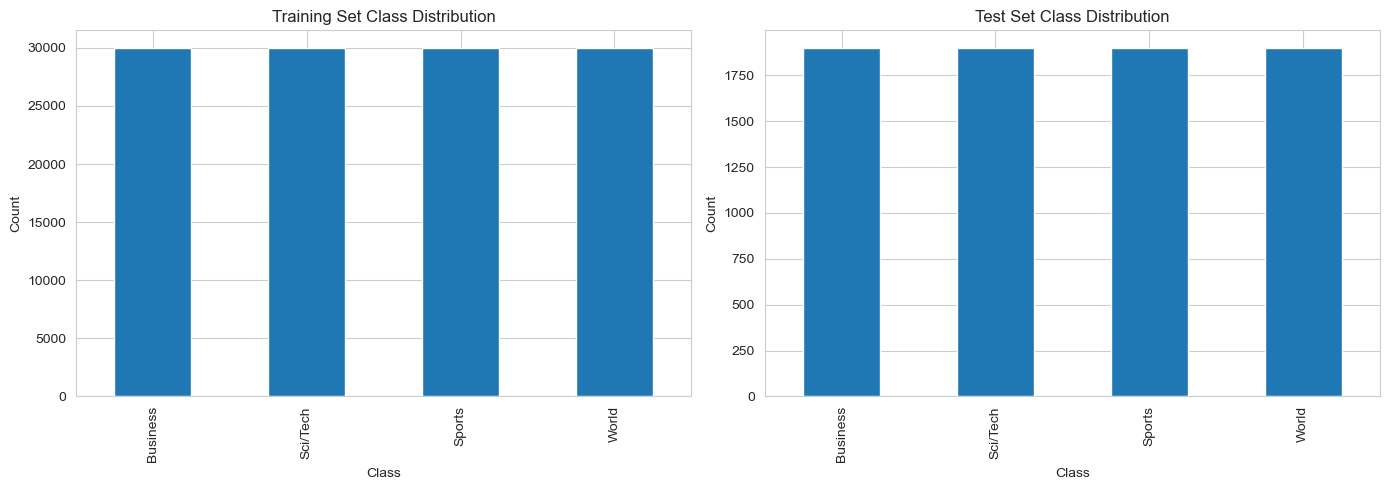

In [4]:
# Class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df['class_name'].value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title('Training Set Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')

test_df['class_name'].value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title('Test Set Class Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('../results/figures/class_distribution.png', dpi=300)
plt.show()

## Text Length Analysis

In [5]:
# Calculate text lengths
train_df['text_length'] = train_df['text'].str.len()
train_df['word_count'] = train_df['text'].str.split().str.len()

print("Text Length Statistics:")
print(train_df[['text_length', 'word_count']].describe())

Text Length Statistics:
         text_length     word_count
count  120000.000000  120000.000000
mean      236.460025      37.844617
std        66.529799      10.088702
min        17.000000       4.000000
25%       196.000000      32.000000
50%       232.000000      37.000000
75%       266.000000      43.000000
max      1012.000000     177.000000


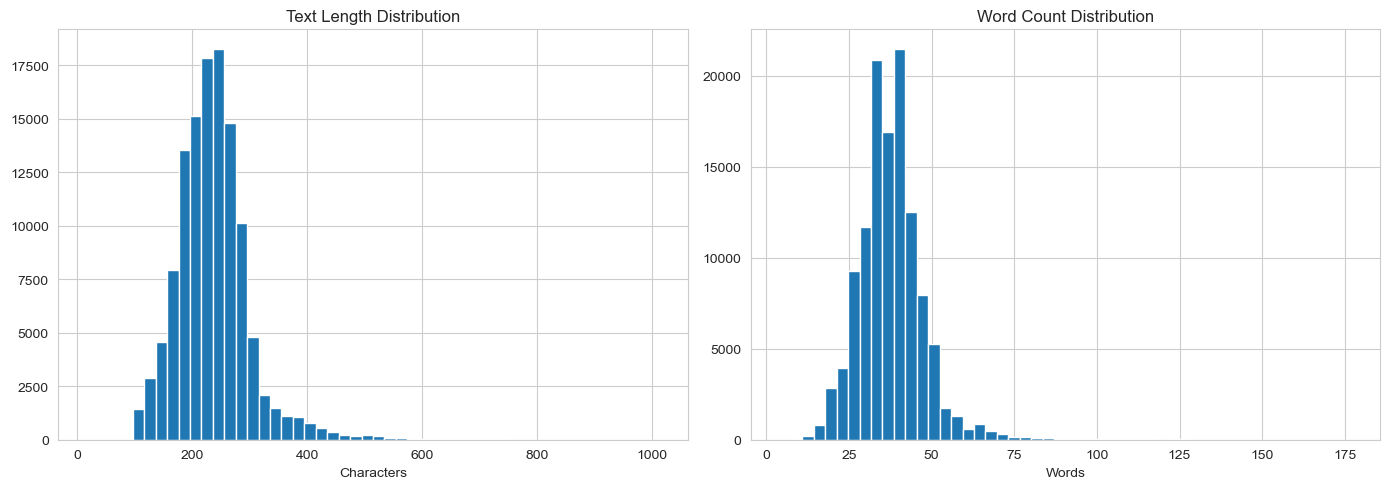

In [6]:
# Plot text length distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df['text_length'].hist(bins=50, ax=axes[0])
axes[0].set_title('Text Length Distribution')
axes[0].set_xlabel('Characters')

train_df['word_count'].hist(bins=50, ax=axes[1])
axes[1].set_title('Word Count Distribution')
axes[1].set_xlabel('Words')

plt.tight_layout()
plt.savefig('../results/figures/text_length_distribution.png', dpi=300)
plt.show()

## Sample Data

In [7]:
# Display samples from each class
for class_name in train_df['class_name'].unique():
    print(f"\n{'='*60}")
    print(f"Class: {class_name}")
    print('='*60)
    sample = train_df[train_df['class_name'] == class_name].iloc[0]
    print(f"Title: {sample['title']}")
    print(f"Description: {sample['description'][:200]}...")


Class: Business
Title: Wall St. Bears Claw Back Into the Black (Reuters)
Description: Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....

Class: Sci/Tech
Title: 'Madden,' 'ESPN' Football Score in Different Ways (Reuters)
Description: Reuters - Was absenteeism a little high\on Tuesday among the guys at the office? EA Sports would like\to think it was because "Madden NFL 2005" came out that day,\and some fans of the football simulat...

Class: Sports
Title: Phelps, Thorpe Advance in 200 Freestyle (AP)
Description: AP - Michael Phelps took care of qualifying for the Olympic 200-meter freestyle semifinals Sunday, and then found out he had been added to the American team for the evening's 400 freestyle relay final...

Class: World
Title: Venezuelans Vote Early in Referendum on Chavez Rule (Reuters)
Description: Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will either remove left-wi

## Save Processed Data

In [8]:
# Save for later use
train_df.to_csv('../data/processed/train_explored.csv', index=False)
test_df.to_csv('../data/processed/test_explored.csv', index=False)
print("Data saved successfully!")

Data saved successfully!
